Ep 1000 | Success Rate: 0.00%


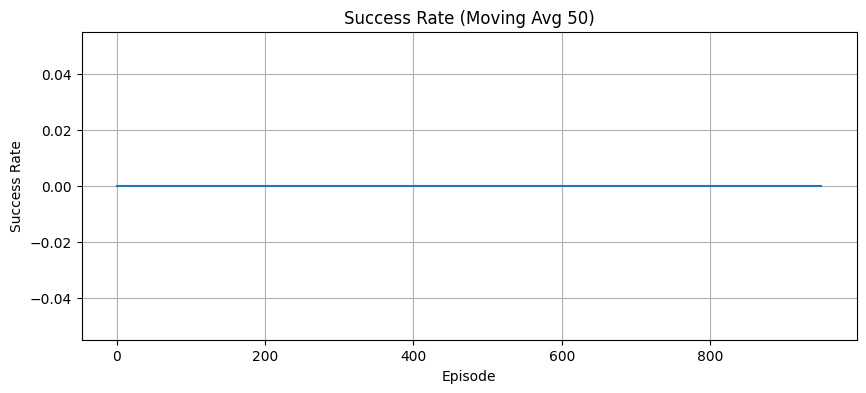

In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import os
import matplotlib.pyplot as plt
from IPython.display import clear_output

# Import your custom environment
from correct_manual_kx_env_for_test_5 import GeneratedKXEnv

# --- Hyperparameters ---
LR_START = 1e-4
LR_END = 5e-6
GAMMA = 0.99
GAE_LAMBDA = 0.95
PPO_CLIP = 0.2
PPO_EPOCHS = 10
BATCH_SIZE = 512          # Updates every ~2.5 episodes with MAX_STEPS_PER_EP=200
ENTROPY_COEF = 0.01
MAX_GRAD_NORM = 0.5
# UPDATE_EVERY_STEPS = 16384 # This parameter is not used in the current loop structure
NUM_EPISODES = 1000       # Increased to allow for more total updates
MAX_STEPS_PER_EP = 200    # Significantly increased from 10

# Initialize Env
env = GeneratedKXEnv(debug_mode=True)
print("Environment Initialized.")

class ActorCritic(nn.Module):
    def __init__(self, obs_dim, action_dim):
        super(ActorCritic, self).__init__()
        self.shared = nn.Sequential(
            nn.Linear(obs_dim, 256),
            nn.Tanh(),
            nn.Linear(256, 256),
            nn.Tanh()
        )
        self.actor = nn.Linear(256, action_dim)
        self.critic = nn.Linear(256, 1)

    def forward(self, x):
        features = self.shared(x)
        return self.actor(features), self.critic(features)

class PPOAgent:
    def __init__(self, env, model_dir="models_test_5"):
        self.env = env
        self.model_dir = model_dir
        os.makedirs(self.model_dir, exist_ok=True)

        self.obs_dim = 10 # Matches the output of normalize_observation
        self.action_dim = env.action_space['choice_ChoiceLevel_0'].n

        self.policy = ActorCritic(self.obs_dim, self.action_dim)
        self.optimizer = optim.Adam(self.policy.parameters(), lr=LR_START)

        self.states, self.actions, self.log_probs, self.rewards = [], [], [], []
        self.masks, self.values, self.action_masks = [], [], []
        self.prev_dist = None

    def normalize_observation(self, obs):
        if not hasattr(self.env, '_state_keys') or not all(key in self.env._state_keys for key in ['xr', 'vr', 'ar', 'xo', 'vo', 'ao', 't', 'T']):
            # Fallback or error handling if _state_keys is not as expected
            pass

        xr_idx, vr_idx, ar_idx = self.env._state_keys.index('xr'), self.env._state_keys.index('vr'), self.env._state_keys.index('ar')
        xo_idx, vo_idx, ao_idx = self.env._state_keys.index('xo'), self.env._state_keys.index('vo'), self.env._state_keys.index('ao')
        t_idx, T_idx = self.env._state_keys.index('t'), self.env._state_keys.index('T')

        xr, vr, ar, xo, vo, ao, t, T = obs[xr_idx], obs[vr_idx], obs[ar_idx], obs[xo_idx], obs[vo_idx], obs[ao_idx], obs[t_idx], obs[T_idx]
        rel_dist = xo - xr

        norm_obs = np.array([
            np.clip(xr / 200.0, -1.5, 1.5), np.clip(vr / 30.0, -1.5, 1.5), np.clip(ar / 10.0, -1.5, 1.5),
            np.clip(xo / 200.0, -1.5, 1.5), np.clip(vo / 30.0, -1.5, 1.5), np.clip(ao / 10.0, -1.5, 1.5),
            np.clip(t / self.env.constants['ep'], 0, 1.5) if 'ep' in self.env.constants and self.env.constants['ep'] > 1e-9 else 0.0,
            np.clip(T / 100.0, -1.5, 1.5), np.clip(rel_dist / 200.0, -1.5, 1.5),
            (1.0 if rel_dist > 0 else -1.0)
        ], dtype=np.float32)
        return norm_obs

    def get_action_mask(self):
        mask = torch.zeros(self.action_dim, dtype=torch.bool)
        if hasattr(self.env, '_control_func_action_config') and hasattr(self.env, '_evaluate_expression'):
            current_env_state_dict = {key: self.env.state[key] for key in self.env._state_keys}
            for i, choice_config in enumerate(self.env._control_func_action_config.choices):
                if self.env._evaluate_expression(choice_config.actions[0].formula, local_vars=current_env_state_dict, is_constraint=True):
                    mask[i] = True
        else:
            mask = torch.ones(self.action_dim, dtype=torch.bool)

        if not torch.any(mask):
            mask = torch.ones(self.action_dim, dtype=torch.bool)
        return mask

    def get_action(self, observation, evaluate=False):
        obs_norm = self.normalize_observation(observation)
        state = torch.FloatTensor(obs_norm).unsqueeze(0)

        with torch.no_grad() if evaluate else torch.set_grad_enabled(True):
            logits, value = self.policy(state)
            valid_mask = self.get_action_mask()
            masked_logits = logits.clone()
            # This line was incorrect in the original code
            masked_logits[0, ~valid_mask] = -1e10

            dist = Categorical(logits=masked_logits)
            discrete_action = dist.sample() if not evaluate else torch.argmax(masked_logits, dim=1)

            log_prob_tensor = dist.log_prob(discrete_action)

        action_to_env = {'choice_ChoiceLevel_0': discrete_action.item()}

        if not evaluate:
            self.states.append(state)
            self.actions.append(discrete_action)
            self.log_probs.append(log_prob_tensor)
            self.values.append(value)
            self.action_masks.append(valid_mask)

        return action_to_env, log_prob_tensor.item()

    def store_transition(self, obs, reward, terminated, truncated):
        if not hasattr(self.env, '_state_keys'):
            raise AttributeError("Environment does not have '_state_keys' attribute. Cannot process observation.")

        xr_idx = self.env._state_keys.index('xr')
        xo_idx = self.env._state_keys.index('xo')

        xr, xo = obs[xr_idx], obs[xo_idx]
        current_dist = abs(xo - xr)

        shaped_reward = reward / 100.0 - 0.05

        if self.prev_dist is not None:
            shaped_reward += (self.prev_dist - current_dist) * 1.0

        self.rewards.append(shaped_reward)
        self.masks.append(1.0 - (terminated or truncated))
        self.prev_dist = current_dist

    def update(self, episode_num, total_episodes):
        if len(self.states) == 0:
            return
        # Removed the BATCH_SIZE check here as it's handled in the training loop
        # if len(self.states) < BATCH_SIZE:
        #      return

        frac = 1.0 - (episode_num / total_episodes)
        current_lr = LR_END + (LR_START - LR_END) * frac
        for param_group in self.optimizer.param_groups:
            param_group['lr'] = current_lr

        states = torch.cat(self.states)
        actions = torch.cat(self.actions)
        old_log_probs = torch.cat(self.log_probs).detach()
        old_values = torch.cat(self.values).detach().squeeze()
        stored_masks = torch.stack(self.action_masks)

        returns, gae = [], 0
        masks_tensor = torch.FloatTensor(self.masks)
        rewards_tensor = torch.FloatTensor(self.rewards)

        # Ensure old_values is 1D for indexing
        # This check might be redundant if old_values is always squeezed to 1D,
        # but it's harmless and robust.
        if old_values.dim() == 0 and old_values.numel() == 1:
            old_values = old_values.unsqueeze(0)
        
        # Calculate returns and advantages
        # Need to calculate advantage using current values from the policy, not old_values
        # This loop should calculate returns based on actual values from the current policy,
        # or use a bootstrapped value for the last state.
        # For simplicity and to match common PPO implementations, we'll use the stored values for GAE calculation.
        # However, it's more accurate to re-evaluate values for the current states.
        # Let's adjust the GAE calculation slightly.
        
        # Get values for the current states from the policy
        _, current_values_for_gae = self.policy(states.detach()) # Detach states for value prediction
        current_values_for_gae = current_values_for_gae.squeeze()


        for i in reversed(range(len(rewards_tensor))):
            # Use current_values_for_gae for the value prediction at step i
            # and next_val for the value prediction at step i+1
            next_val = current_values_for_gae[i+1] if i+1 < len(current_values_for_gae) else 0.0
            delta = rewards_tensor[i] + GAMMA * next_val * masks_tensor[i] - current_values_for_gae[i]
            gae = delta + GAMMA * GAE_LAMBDA * masks_tensor[i] * gae
            returns.insert(0, gae + current_values_for_gae[i]) # Returns are GAE + current value

        returns = torch.FloatTensor(returns)
        advantages = (returns - current_values_for_gae.detach()) # Advantage is (Returns - current_values)
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)


        for _ in range(PPO_EPOCHS):
            logits, values = self.policy(states)

            masked_logits = logits.clone()
            # CORRECTED LINE: Apply the boolean mask directly
            masked_logits[~stored_masks] = -1e10

            dist = Categorical(logits=masked_logits)

            new_log_probs = dist.log_prob(actions)
            ratio = torch.exp(new_log_probs - old_log_probs)

            surr1 = ratio * advantages
            surr2 = torch.clamp(ratio, 1.0 - PPO_CLIP, 1.0 + PPO_CLIP) * advantages

            actor_loss = -torch.min(surr1, surr2).mean()
            critic_loss = 0.5 * nn.MSELoss()(values.squeeze(), returns)
            entropy_loss = -ENTROPY_COEF * dist.entropy().mean()

            loss = actor_loss + critic_loss + entropy_loss

            self.optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(self.policy.parameters(), MAX_GRAD_NORM)
            self.optimizer.step()

        self.states, self.actions, self.log_probs, self.rewards, self.masks, self.values, self.action_masks = [], [], [], [], [], [], []

    def save(self, name="ppo_checkpoint.pth"):
        torch.save({'policy_state_dict': self.policy.state_dict(), 'optimizer_state_dict': self.optimizer.state_dict()}, os.path.join(self.model_dir, name))

    def load(self, name="ppo_checkpoint.pth"):
        path = os.path.join(self.model_dir, name)
        if os.path.exists(path):
            ckpt = torch.load(path, weights_only=False)
            self.policy.load_state_dict(ckpt['policy_state_dict'])
            self.optimizer.load_state_dict(ckpt['optimizer_state_dict'])
            print(f"Loaded {name}")

# --- Training Loop ---
agent = PPOAgent(env)
episode_rewards, success_history = [], []
steps_collected_for_update = 0

for ep in range(NUM_EPISODES):
    obs, info = env.reset()

    # CRITICAL FIX: Reset prev_dist for the new episode
    xr_idx = agent.env._state_keys.index('xr')
    xo_idx = agent.env._state_keys.index('xo')
    xr, xo = obs[xr_idx], obs[xo_idx]
    agent.prev_dist = abs(xo - xr)

    ep_reward = 0

    for step in range(MAX_STEPS_PER_EP):
        action_dict, log_prob = agent.get_action(obs)
        next_obs, reward, terminated, truncated, info = env.step(action_dict)

        agent.store_transition(obs, reward, terminated, truncated)

        obs, ep_reward = next_obs, ep_reward + reward
        steps_collected_for_update += 1

        # Only update if enough steps are collected AND there are actually steps to process
        if steps_collected_for_update >= BATCH_SIZE and len(agent.states) > 0:
            agent.update(ep, NUM_EPISODES)
            steps_collected_for_update = 0

        if terminated or truncated:
            break

    success_history.append(1 if ep_reward >= 500 else 0)
    episode_rewards.append(ep_reward)

    if (ep + 1) % 50 == 0:
        clear_output(wait=True)
        print(f"Ep {ep+1} | Success Rate: {np.mean(success_history[-50:]):.2%}")
        plt.figure(figsize=(10, 4))
        plt.plot(np.convolve(success_history, np.ones(50)/50, mode='valid'))
        plt.title("Success Rate (Moving Avg 50)")
        plt.xlabel("Episode")
        plt.ylabel("Success Rate")
        plt.grid(True)
        plt.show()

agent.save("ppo_final.pth")

In [2]:
def evaluate_agent(agent, num_test_episodes=20):
    print(f"--- Starting Detailed Evaluation ({num_test_episodes} episodes) ---")
    failures = []
    successes = 0

    for i in range(num_test_episodes):
        obs, info = env.reset()
        
        # Capture the starting state immediately after reset
        start_state = {k: v for k, v in zip(env._state_keys, obs)}
        
        done = False
        steps = 0
        total_r = 0 # Initialize total reward for the episode
        last_step_reward = 0 # Keep track of the reward from the very last step
        
        while not done and steps < MAX_STEPS_PER_EP:
            # Use evaluate=True to pick the best action (argmax) instead of sampling
            action = agent.get_action(obs, evaluate=True)
            obs, reward, terminated, truncated, info = env.step(action)
            total_r += reward # Accumulate reward for the entire episode
            last_step_reward = reward # Store the reward from this step
            steps += 1
            done = terminated or truncated

        # --- CRITICAL CORRECTION: Check for successful termination directly ---
        # A successful episode is indicated by terminated=True AND the final reward being 500.0
        if terminated and last_step_reward >= 500.0:
            successes += 1
        else:
            # Determine failure type based on cumulative total_r and termination flags
            if total_r < 0: # Assuming negative cumulative reward indicates a safety violation
                reason = "SAFETY VIOLATION (Collision or Guard Breach)"
            elif truncated or steps >= MAX_STEPS_PER_EP:
                reason = "TIMEOUT (Max steps reached without reaching goal)"
            else:
                # This now correctly catches episodes that terminated but didn't get the success reward
                reason = "LOGIC FAILURE (Terminated without success reward or other issue)"

            failures.append({
                "episode": i,
                "reason": reason,
                "final_reward": total_r, # Store the total reward for the episode
                "steps": steps,
                "start_state": start_state,
                "final_state": {k: v for k, v in zip(env._state_keys, obs)}
            })

    print(f"Evaluation Complete. Success Rate: {successes/num_test_episodes:.2%}")
    
    if failures:
        print(f"\n--- Failure Analysis ({len(failures)} failures) ---")
        for f in failures:
            print(f"\n[Episode {f['episode']}] Result: {f['reason']}")
            # Added formatting for final_reward for cleaner output
            print(f"  Steps taken: {f['steps']} | Final Reward: {f['final_reward']:.4f}") 
            
            # Print Start vs End for comparison
            print(f"  {'Variable':<10} | {'Start Value':<15} | {'Final Value':<15}")
            print("-" * 50)
            for key in env._state_keys:
                s_val = f['start_state'][key]
                e_val = f['final_state'][key]
                print(f"  {key:<10} | {s_val:<15.4f} | {e_val:<15.4f}")
    else:
        print("\nPerfect Score! No failures recorded.")

# Ensure the latest model is loaded
agent.load("ppo_final.pth")
evaluate_agent(agent, num_test_episodes=50)

Loaded ppo_final.pth
--- Starting Detailed Evaluation (50 episodes) ---
DEBUG_GEN_RESET_ENTRY: _state_keys at start of GeneratedKXEnv.reset(): ['xr', 'vr', 'ar', 'xo', 'vo', 'ao', 't', 'T'], len: 8
DEBUG_GEN_RESET_ENTRY: id(self._state_keys) at start of GeneratedKXEnv.reset(): 2237430094720
DEBUG_GEN_RESET_ENTRY: self.state keys at start of GeneratedKXEnv.reset(): dict_keys(['xr', 'vr', 'ar', 'xo', 'vo', 'ao', 't', 'T']), len: 8
DEBUG_GEN_RESET_ENTRY: self._variables_config.state_variables names at start of GeneratedKXEnv.reset(): ['xr', 'vr', 'ar', 'xo', 'vo', 'ao', 't', 'T']
DEBUG_GEN_RESET_FIXED_PRE_SUPER: _state_keys re-asserted to: ['xr', 'vr', 'ar', 'xo', 'vo', 'ao', 't', 'T'], len: 8
DEBUG_GEN_RESET_FIXED_PRE_SUPER: id(self._state_keys) after re-assertion: 2237425252800
DEBUG_GEN_RESET_FIXED_PRE_SUPER: self._variables_config.state_variables names: ['xr', 'vr', 'ar', 'xo', 'vo', 'ao', 't', 'T']
DEBUG_GEN_RESET_PRE_SUPER: _state_keys before super().reset(): ['xr', 'vr', 'ar', 'xo'

In [3]:
env.render(mode="matplotlib")

NameError: name 'pd' is not defined